# Experimento exploratório com V-JEPA 2 em recortes de orelhas de gatos

Este notebook documenta o experimento complementar apresentado na seção 11 do `TCC_FINAL_REVISADO.ipynb`. O objetivo é extrair representações visuais de dois recortes de orelhas previamente anotadas, um de cada classe:

- **`0 — orelha_marcada`:** orelha com marcação visível.
- **`1 — orelha_normal`:** orelha sem marcação visível.

O V-JEPA 2 é utilizado exclusivamente como extrator de características, sem ajuste fino e sem treinamento de um classificador. A análise apresenta a similaridade de cosseno entre duas amostras, os tempos de processamento e uma visualização dos vetores obtidos. Diferentemente do YOLO11s, o experimento não realiza detecção de orelhas em fotografias completas.

**Nota de reprodutibilidade.** A execução é independente do notebook principal, em um ambiente Python exclusivo com PyTorch para CPU. Os resultados deverão ser gerados na execução deste arquivo; as saídas de execuções anteriores não foram incorporadas à cópia.


## 1. Ambiente de execução

O V-JEPA 2 utiliza um ambiente virtual próprio, separado do ambiente CUDA empregado no treinamento do YOLO11s. Os comandos abaixo devem ser executados **no terminal PowerShell do VS Code**, e não em células Python. Caso o ambiente `.venv_vjepa` já exista, não é necessário criá-lo novamente.

```powershell
cd "C:\Users\barba\OneDrive\Documentos\TCC_limpo"
& "C:\Users\barba\AppData\Local\Python\pythoncore-3.13-64\python.exe" -m venv .venv_vjepa
& ".\.venv_vjepa\Scripts\python.exe" -m pip install --upgrade pip
& ".\.venv_vjepa\Scripts\python.exe" -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu
& ".\.venv_vjepa\Scripts\python.exe" -m pip install transformers huggingface_hub accelerate safetensors scikit-learn pillow pandas numpy matplotlib ipykernel
& ".\.venv_vjepa\Scripts\python.exe" -m ipykernel install --user --name tcc-vjepa2 --display-name "Python (TCC V-JEPA 2)"
```

No canto superior direito, selecione o kernel **Python (TCC V-JEPA 2)** e reinicie-o antes de executar o experimento. A etapa seguinte verifica o interpretador e as versões instaladas.

**Atenção.** A instalação de bibliotecas deve permanecer isolada de `.venv_yolo`. O carregamento do modelo pré-treinado pode exigir muita memória RAM e espaço de paginação. Se o ambiente já estiver funcionando, não reinstale o PyTorch sem necessidade.


In [1]:

# 1 - VERIFICAÇÃO DO AMBIENTE V-JEPA 2

from pathlib import Path
import sys
import importlib.metadata as metadata

BASE_DIR = Path(r"C:\Users\barba\OneDrive\Documentos\TCC_limpo")
SAIDA_VJEPA = BASE_DIR / "resultados_vjepa_exploratorio"
SAIDA_VJEPA.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("Projeto:", BASE_DIR)
print("Saída:", SAIDA_VJEPA)
if "venv_vjepa" not in sys.executable.lower():
    raise RuntimeError(
        "Selecione o kernel 'Python (TCC V-JEPA 2)' antes de continuar. "
        "Não execute no Python global do YOLO11s."
    )
for pacote in ("torch", "transformers", "torchvision", "scikit-learn", "ipykernel"):
    try:
        print(f"{pacote}: {metadata.version(pacote)}")
    except metadata.PackageNotFoundError:
        print(f"{pacote}: NÃO INSTALADO")

Python: c:\Users\barba\OneDrive\Documentos\TCC_limpo\.venv_vjepa\Scripts\python.exe
Projeto: C:\Users\barba\OneDrive\Documentos\TCC_limpo
Saída: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_vjepa_exploratorio
torch: 2.13.0+cpu
transformers: 5.22.1
torchvision: 0.28.0+cpu
scikit-learn: 1.9.1
ipykernel: 7.4.0


## 2. Configuração do experimento

O experimento utiliza o modelo pré-treinado `facebook/vjepa2-vitl-fpc64-256` e execução em CPU. Cada imagem estática é posteriormente repetida em dois quadros para atender à interface de entrada de vídeo. Os caminhos do conjunto de dados, as classes e os parâmetros são definidos na célula seguinte.

Os tempos registrados dependem do hardware e da carga do computador e não são diretamente comparáveis aos tempos de inferência do YOLO11s em GPU.


In [2]:

# 2 - PARÂMETROS E DIRETÓRIOS DO EXPERIMENTO

import torch
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from time import perf_counter
from IPython.display import display
from transformers import AutoModel, AutoVideoProcessor

MODELO_VJEPA = "facebook/vjepa2-vitl-fpc64-256"
FRAMES_REPETIDOS = 2
DEVICE_VJEPA = torch.device("cpu")
NOMES_CLASSES_VJEPA = {0: "orelha_marcada", 1: "orelha_normal"}

DATASET = BASE_DIR / "dataset_yolo_20261103_151141_523409"
if (
    not (DATASET / "images" / "train").is_dir()
    or not (DATASET / "labels" / "train").is_dir()
):
    raise FileNotFoundError(
        f"Dataset não encontrado: {DATASET}. "
        "Ajuste DATASET para a pasta com images/train e labels/train."
    )
print("Modelo:", MODELO_VJEPA)
print("Dataset:", DATASET)
print("Dispositivo:", DEVICE_VJEPA)
print("Frames repetidos:", FRAMES_REPETIDOS)

c:\Users\barba\OneDrive\Documentos\TCC_limpo\.venv_vjepa\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo: facebook/vjepa2-vitl-fpc64-256
Dataset: C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409
Dispositivo: cpu
Frames repetidos: 2


## 3. Seleção das amostras anotadas

Foram previstas duas amostras retiradas do conjunto de treinamento, uma de cada classe, utilizando `random_state=42`. As caixas das anotações YOLO delimitam as regiões que serão apresentadas ao V-JEPA 2.

A escolha de apenas dois recortes é adequada à demonstração do procedimento, mas não permite avaliar o desempenho de classificação ou a capacidade de generalização do modelo.


In [3]:
# 3 - SELEÇÃO DE DUAS AMOSTRAS ANOTADAS

EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
registros = []
PASTA_IMAGENS = DATASET / "images" / "train"
PASTA_LABELS = DATASET / "labels" / "train"

for imagem in sorted(PASTA_IMAGENS.rglob("*")):
    if not imagem.is_file() or imagem.suffix.lower() not in EXTS:
        continue
    relativo = imagem.relative_to(PASTA_IMAGENS)
    anotacao = (PASTA_LABELS / relativo).with_suffix(".txt")
    if not anotacao.is_file():
        continue
    try:
        with Image.open(imagem) as origem:
            largura, altura = ImageOps.exif_transpose(origem).size
        for linha in anotacao.read_text(encoding="utf-8").splitlines():
            partes = linha.strip().split()
            if len(partes) != 5:
                continue
            classe = int(partes[0])
            if classe not in NOMES_CLASSES_VJEPA:
                continue
            xc, yc, w, h = map(float, partes[1:])
            x1 = max(0, int((xc - w / 2) * largura))
            y1 = max(0, int((yc - h / 2) * altura))
            x2 = min(largura, int((xc + w / 2) * largura))
            y2 = min(altura, int((yc + h / 2) * altura))
            if x2 > x1 and y2 > y1:
                registros.append(
                    {
                        "imagem": str(imagem),
                        "x1": x1,
                        "y1": y1,
                        "x2": x2,
                        "y2": y2,
                        "classe": classe,
                    }
                )
    except (OSError, ValueError) as erro:
        print("Imagem/anotação ignorada:", imagem.name, erro)

dados = pd.DataFrame(registros)
if dados.empty or not {0, 1}.issubset(set(dados["classe"])):
    raise ValueError(
        "É necessário ter ao menos uma anotação de cada classe "
        "no conjunto de treinamento."
    )
amostras_teste = pd.concat(
    [
        dados[dados["classe"] == 0].sample(n=1, random_state=42),
        dados[dados["classe"] == 1].sample(n=1, random_state=42),
    ],
    ignore_index=True,
)
print("Total de recortes anotados:", len(dados))
display(amostras_teste)

Total de recortes anotados: 644


,imagem,x1,y1,x2,y2,classe
0,C:\Users\barba\OneDrive\Documentos\TCC_limpo\d...,41,9,99,58,0
1,C:\Users\barba\OneDrive\Documentos\TCC_limpo\d...,411,514,584,654,1


## 4. Carregamento do V-JEPA 2

A célula seguinte carrega o processador de vídeo e os pesos pré-treinados. O modelo permanece congelado, sem atualização de parâmetros pelas fotografias do TCC. Na primeira execução, os arquivos podem precisar ser baixados.

**Observação.** O carregamento pode exigir memória RAM e memória virtual consideráveis. A etapa não deve ser executada simultaneamente aos treinamentos YOLO11s.


In [4]:
# 4- CARREGAMENTO DO MODELO PRÉ-TREINADO

processador_vjepa = AutoVideoProcessor.from_pretrained(MODELO_VJEPA)
modelo_vjepa = (
    AutoModel.from_pretrained(MODELO_VJEPA, torch_dtype=torch.float32)
    .to(DEVICE_VJEPA)
    .eval()
)
modelo_vjepa.requires_grad_(False)
params_vjepa = sum(p.numel() for p in modelo_vjepa.parameters())
print(f"Modelo carregado: {MODELO_VJEPA}")
print(f"Parâmetros: {params_vjepa:,}")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 587/587 [00:02<00:00, 246.44it/s]


Modelo carregado: facebook/vjepa2-vitl-fpc64-256
Parâmetros: 325,971,328


## 5. Extração dos embeddings dos recortes

Cada recorte é duplicado em dois quadros idênticos para ser fornecido ao modelo, sem introduzir informação temporal. O vetor representativo é obtido pela média das representações dos tokens retornados pelo codificador.

Os vetores, as classes e os tempos de processamento são armazenados para análise exploratória.


In [5]:
# 5 - EXTRAÇÃO DOS EMBEDDINGS

def embedding_orelha(linha):
    with Image.open(linha["imagem"]) as origem:
        imagem = ImageOps.exif_transpose(origem).convert("RGB")
        recorte = imagem.crop(
            (
                int(linha["x1"]),
                int(linha["y1"]),
                int(linha["x2"]),
                int(linha["y2"]),
            )
        )
        quadro = np.asarray(recorte)
    video_estatico = np.repeat(quadro[None, :, :, :], FRAMES_REPETIDOS, axis=0)
    entradas = processador_vjepa(video_estatico, return_tensors="pt")
    entradas = {k: v.to(DEVICE_VJEPA) for k, v in entradas.items()}
    with torch.inference_mode():
        saida = modelo_vjepa(**entradas, skip_predictor=True)
        vetor = saida.last_hidden_state.mean(dim=1).squeeze(0)
    return vetor.float().cpu().numpy()

embeddings_exploratorios = []
tempos_exploratorios = []
classes_exploratorias = []
for i, (_, linha) in enumerate(amostras_teste.iterrows(), start=1):
    inicio = perf_counter()
    vetor = embedding_orelha(linha)
    duracao = perf_counter() - inicio
    embeddings_exploratorios.append(vetor)
    tempos_exploratorios.append(duracao)
    classes_exploratorias.append(int(linha["classe"]))
    print(
        f"[{i}/{len(amostras_teste)}] "
        f"{NOMES_CLASSES_VJEPA[int(linha['classe'])]}: "
        f"embedding={vetor.shape}; tempo={duracao:.2f}s",
        flush=True,
    )
embeddings_exploratorios = np.stack(embeddings_exploratorios)
print("Dimensões:", embeddings_exploratorios.shape)

[1/2] orelha_marcada: embedding=(1024,); tempo=1.09s
[2/2] orelha_normal: embedding=(1024,); tempo=0.72s
Dimensões: (2, 1024)


## 6. Similaridade de cosseno e armazenamento dos resultados

A similaridade de cosseno é calculada entre os dois embeddings. Essa medida descreve a relação entre os vetores obtidos, mas **não representa acurácia, precisão, recall ou mAP**.

São salvos os embeddings, a matriz de similaridade e o registro dos tempos de extração para permitir análise posterior sem necessariamente carregar novamente o modelo.


In [6]:
# 6 - SIMILARIDADE E SALVAMENTO DOS DADOS

from sklearn.metrics.pairwise import cosine_similarity
similaridade = cosine_similarity(embeddings_exploratorios)
print("Matriz de similaridade:\n", similaridade)

np.save(SAIDA_VJEPA / "embeddings_vjepa.npy", embeddings_exploratorios)
np.save(SAIDA_VJEPA / "similaridade_cosseno.npy", similaridade)
pd.DataFrame(
    {
        "classe": classes_exploratorias,
        "classe_nome": [NOMES_CLASSES_VJEPA[c] for c in classes_exploratorias],
        "imagem": amostras_teste["imagem"].astype(str),
        "tempo_segundos": tempos_exploratorios,
    }
).to_csv(
    SAIDA_VJEPA / "tempos_vjepa.csv",
    index=False,
    encoding="utf-8-sig",
)
print("Arquivos salvos em:", SAIDA_VJEPA)

Matriz de similaridade:
 [[0.99999976 0.5009876 ]
 [0.5009876  0.99999976]]
Arquivos salvos em: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_vjepa_exploratorio


## 7. Visualização dos resultados exploratórios

O painel reúne os dois recortes, a matriz de similaridade, os tempos de extração em CPU e parte das dimensões dos embeddings. A figura pode ser utilizada como documentação visual no TCC, respeitando o caráter exploratório da análise.


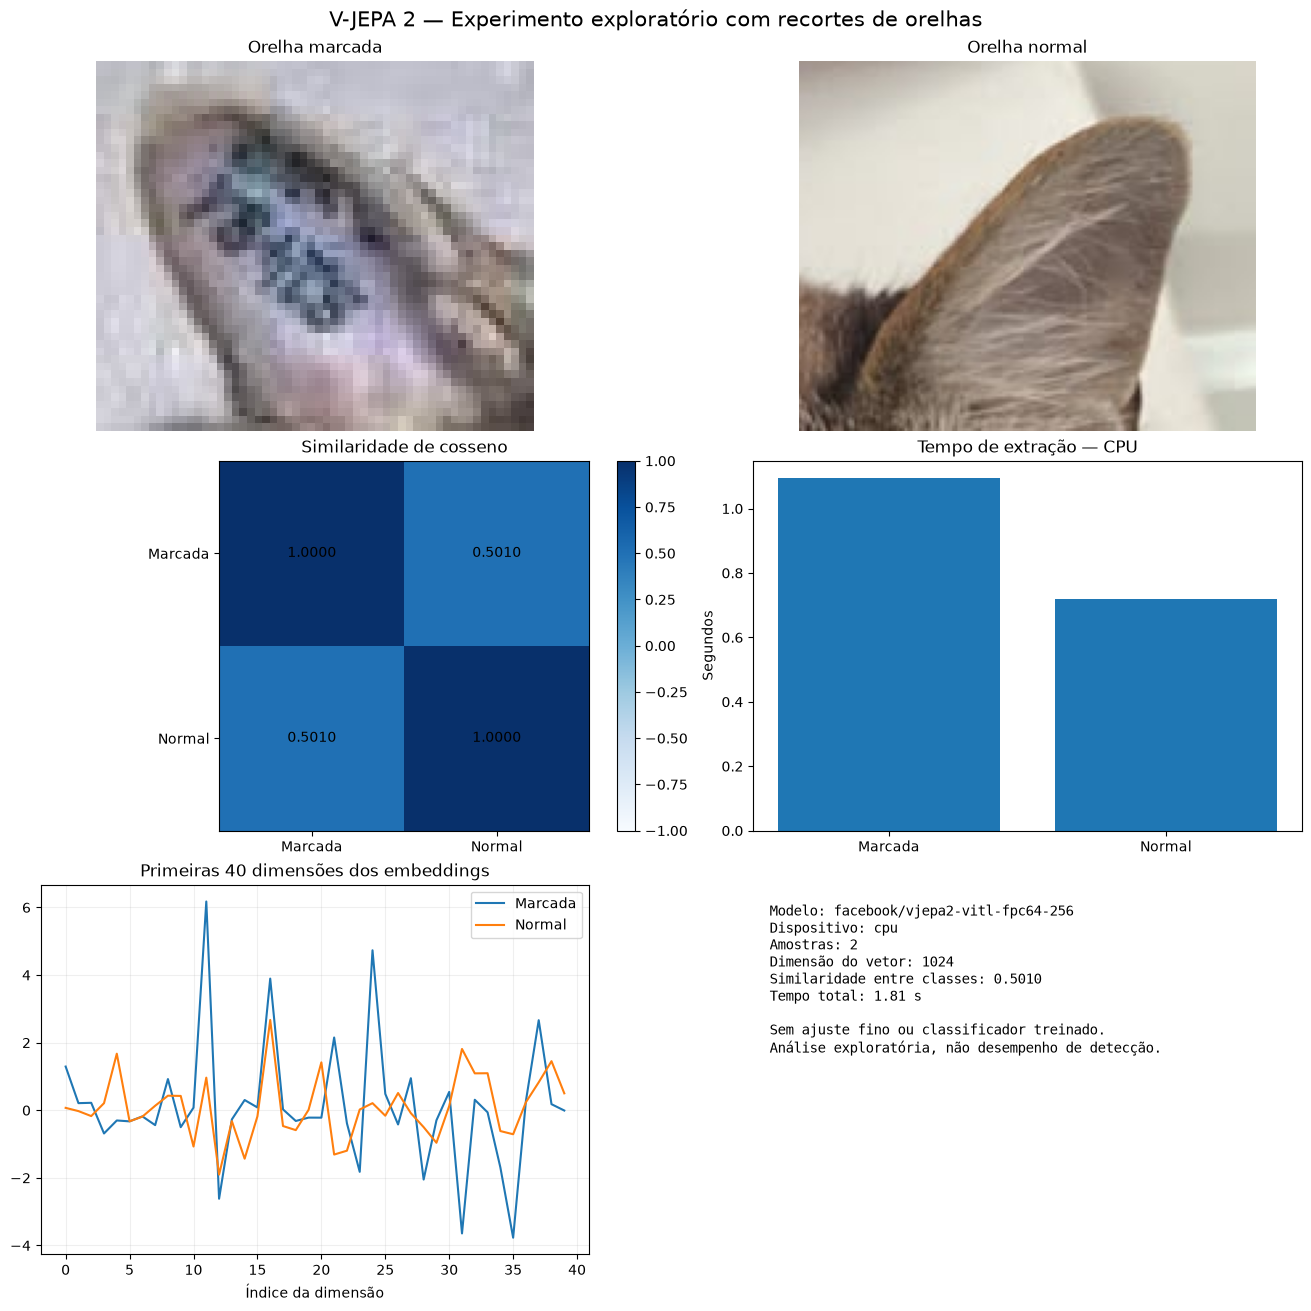

Painel salvo: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_vjepa_exploratorio\painel_visual_vjepa2.png


In [7]:
# 7- PAINEL VISUAL DOS RESULTADOS

import matplotlib.pyplot as plt

recortes = []
for _, linha in amostras_teste.iterrows():
    with Image.open(linha["imagem"]) as origem:
        imagem = ImageOps.exif_transpose(origem).convert("RGB")
        recortes.append(
            imagem.crop(
                (
                    int(linha["x1"]),
                    int(linha["y1"]),
                    int(linha["x2"]),
                    int(linha["y2"]),
                )
            ).copy()
        )

fig, axes = plt.subplots(3, 2, figsize=(13, 13), layout="constrained")
for k in range(2):
    axes[0, k].imshow(recortes[k])
    axes[0, k].set_title("Orelha marcada" if k == 0 else "Orelha normal")
    axes[0, k].axis("off")

ax = axes[1, 0]
img = ax.imshow(similaridade, cmap="Blues", vmin=-1, vmax=1)
ax.set_xticks([0, 1], ["Marcada", "Normal"])
ax.set_yticks([0, 1], ["Marcada", "Normal"])
ax.set_title("Similaridade de cosseno")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{similaridade[i, j]:.4f}", ha="center", va="center")
fig.colorbar(img, ax=ax, fraction=0.046)

axes[1, 1].bar(["Marcada", "Normal"], tempos_exploratorios)
axes[1, 1].set_title("Tempo de extração — CPU")
axes[1, 1].set_ylabel("Segundos")

n_dim = min(40, embeddings_exploratorios.shape[1])
for k, nome in enumerate(["Marcada", "Normal"]):
    axes[2, 0].plot(range(n_dim), embeddings_exploratorios[k, :n_dim], label=nome)
axes[2, 0].set_title(f"Primeiras {n_dim} dimensões dos embeddings")
axes[2, 0].set_xlabel("Índice da dimensão")
axes[2, 0].legend()
axes[2, 0].grid(alpha=0.2)
axes[2, 1].axis("off")
axes[2, 1].text(
    0.03,
    0.95,
    (
    f"Modelo: {MODELO_VJEPA}\n"
    f"Dispositivo: {DEVICE_VJEPA}\n"
    f"Amostras: {len(amostras_teste)}\n"
    f"Dimensão do vetor: {embeddings_exploratorios.shape[1]}\n"
    f"Similaridade entre classes: {similaridade[0, 1]:.4f}\n"
    f"Tempo total: {sum(tempos_exploratorios):.2f} s\n\n"
    "Sem ajuste fino ou classificador treinado.\n"
    "Análise exploratória, não desempenho de detecção."
    ),
    va="top",
    family="monospace",
    fontsize=10,
    transform=axes[2, 1].transAxes,
)
fig.suptitle("V-JEPA 2 — Experimento exploratório com recortes de orelhas", fontsize=15)
arquivo_painel = SAIDA_VJEPA / "painel_visual_vjepa2.png"
fig.savefig(arquivo_painel, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Painel salvo:", arquivo_painel)

## 8. Registro dos metadados do experimento

Os metadados identificam o modelo, o ambiente, o conjunto de dados, as amostras selecionadas, os parâmetros e os resultados desta execução. O registro permite rastrear os arquivos produzidos e explicitar as limitações metodológicas.


In [8]:
# 8- METADADOS E REPRODUTIBILIDADE

import json
import platform
from datetime import datetime

metadados = {
    "experimento": "V-JEPA 2 — análise exploratória",
    "data_execucao": datetime.now().isoformat(timespec="seconds"),
    "modelo": MODELO_VJEPA,
    "dataset": str(DATASET),
    "split": "train",
    "dispositivo": str(DEVICE_VJEPA),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": metadata.version("transformers"),
    "frames_repetidos": FRAMES_REPETIDOS,
    "modelo_congelado": True,
    "parametros_modelo": int(params_vjepa),
    "amostras": [
        {
            "imagem": str(linha["imagem"]),
            "classe": NOMES_CLASSES_VJEPA[int(linha["classe"])],
            "caixa_xyxy": [int(linha[k]) for k in ["x1", "y1", "x2", "y2"]],
            "tempo_segundos": float(tempos_exploratorios[i]),
        }
        for i, (_, linha) in enumerate(amostras_teste.iterrows())
    ],
    "dimensoes_embeddings": list(embeddings_exploratorios.shape),
    "similaridade_cosseno": float(similaridade[0, 1]),
    "limitacao": "Apenas duas amostras anotadas; sem classificador ou avaliação quantitativa de detecção."
}
(SAIDA_VJEPA / "metadados_vjepa2.json").write_text(
    json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Experimento documentado em:", SAIDA_VJEPA.resolve())

Experimento documentado em: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_vjepa_exploratorio


## 9. Interpretação e limitações do experimento

O V-JEPA 2 pré-treinado permite gerar vetores numéricos a partir dos recortes anotados, porém **a comparação entre apenas duas orelhas não demonstra que o modelo distingue orelhas marcadas e normais**. Não houve ajuste fino, treinamento de classificador nem avaliação quantitativa de detecção.

A análise deve ser apresentada no TCC como experimento complementar, e não como substituição das métricas do YOLO11s. Uma possível continuidade seria extrair embeddings de um conjunto maior e avaliar um classificador, com separação adequada entre treinamento, validação e teste.

**Arquivos gerados:** `resultados_vjepa_exploratorio/embeddings_vjepa.npy`, `similaridade_cosseno.npy`, `tempos_vjepa.csv`, `painel_visual_vjepa2.png` e `metadados_vjepa2.json`.

**Nota de reprodutibilidade.** Uma nova execução pode produzir tempos diferentes e selecionar imagens diferentes caso o dataset seja alterado.
